# Chapitre 8 - Exercices 8.7 à 8.10

Ce notebook traite les derniers exercices du chapitre 8, centrés sur l'usage des
horloges, les baux et le raisonnement sur la correction :

- **8.7** : LWW et écritures perdues, mesure et correction (calcul et simulation) ;
- **8.8** : commit wait de Spanner, attente et débit (calcul) ;
- **8.9** : bail, pause et marge, et ce que change la clôture (calcul et simulation) ;
- **8.10** : majorités, menteurs et propriétés de sûreté ou de vivacité
  (raisonnement).

In [1]:
import itertools
import math
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## Exercice 8.7 : LWW et écritures perdues, mesure et correction

**Énoncé.** Une clé (le profil d'un utilisateur) est répliquée sur deux nœuds A et B qui
résolvent les conflits par LWW avec leur horloge calendaire. L'horloge de B **retarde** de
30 ms sur celle de A. Les mises à jour arrivent l'une après l'autre (intervalles
exponentiels de moyenne 100 ms), chacune sur A ou B avec probabilité 1/2.

1. Une écriture sur B est perdue si l'écriture **précédente** a eu lieu sur A moins de
   30 ms avant. En négligeant les chaînes plus longues, estimer la proportion d'écritures
   perdues.
2. Vérifier par simulation (`ds.lww_lost_writes`), puis tracer la proportion perdue en
   fonction de l'écart des horloges, de 0,1 à 300 ms.
3. Correction : chaque nœud lit l'horodatage courant et prend
   $\max(\text{horloge locale}, \text{horodatage lu} + \epsilon)$. Montrer qu'aucune écriture
   n'est plus perdue. Quel est le coût ? Que deviennent les horodatages ?

**Rappels.** Horodater pour ordonner, défauts de LWW (cours 3, section 4 ; section
*Timestamps for ordering events*) ; LWW et réplication multi-leader (chapitre
5).

**Solution.**

*1.* Il faut : écriture précédente sur A (probabilité 1/2), écriture courante sur B (1/2),
et un écart inférieur à 30 ms : $1 - e^{-30/100} \approx 0{,}259$. Soit
$\frac{1}{4} \times 0{,}259 \approx 6{,}5\,\%$ des écritures perdues, **sans aucune erreur**.

*2.* La simulation (ci-dessous) donne un peu plus, car une écriture sur B peut aussi être
masquée par une écriture sur A plus ancienne que la précédente (chaînes B après A après
B...).

*3.* Avec la règle du maximum, chaque nouvel horodatage dépasse celui de la valeur qu'il
remplace : l'ordre des horodatages suit l'ordre réel des écritures successives, et aucune
n'est perdue. Le coût : une **lecture** avant chaque écriture (un aller-retour de plus, que
Cassandra et ScyllaDB évitent justement), et des horodatages qui ne sont plus l'heure :
ils sont tirés vers l'horloge la plus en avance. C'est le principe d'une horloge
**logique** (ou hybride), qui ordonne sans prétendre mesurer le temps (chapitre
9).

approximation : 6.48% ; simulation : 6.99%


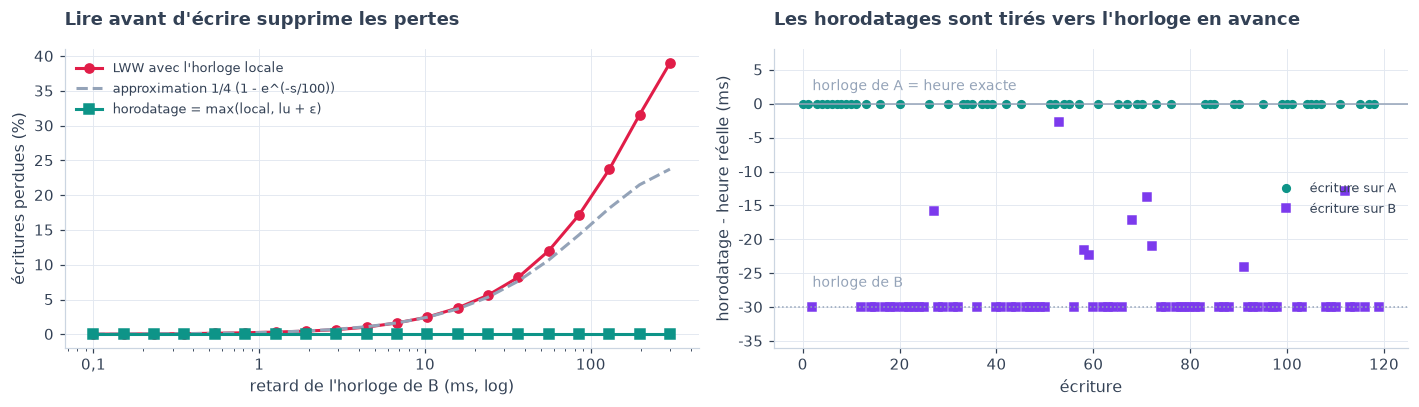

In [2]:
approx = 0.25 * (1 - math.exp(-30 / 100))
sim = ds.lww_lost_writes(30.0, n_writes=200_000, mean_gap=100.0, n_nodes=2, seed=1)["perdues"]
print(f"approximation : {approx:.2%} ; simulation : {sim:.2%}")


def lww_avec_max(skew, n=200_000, gap=100.0, seed=1, eps=1e-3):
    """Écritures successives, horodatage = max(horloge locale, horodatage courant + eps)."""
    r = np.random.default_rng(seed)
    t = np.cumsum(r.exponential(gap, n))
    node = r.integers(0, 2, n)
    clock = t + np.where(node == 0, 0.0, -skew)
    ts = np.empty(n)
    cur = -np.inf
    for i in range(n):
        ts[i] = max(clock[i], cur + eps)
        cur = ts[i]
    perdues = np.mean(ts < np.maximum.accumulate(np.r_[-np.inf, ts[:-1]]))
    return perdues, ts - t, node

skews = np.logspace(-1, np.log10(300), 20)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
ax.semilogx(skews, [ds.lww_lost_writes(s, n_writes=50_000, mean_gap=100.0, seed=2)["perdues"] * 100 for s in skews],
            "o-", color=ROSE, label="LWW avec l'horloge locale")
ax.semilogx(skews, 25 * (1 - np.exp(-skews / 100)), "--", color=GRAY, label="approximation 1/4 (1 - e^(-s/100))")
ax.semilogx(skews, [lww_avec_max(s, n=20_000)[0] * 100 for s in skews], "s-", color=TEAL, label="horodatage = max(local, lu + ε)")
plain_log_axis(ax, "x")
ax.set_xlabel("retard de l'horloge de B (ms, log)"); ax.set_ylabel("écritures perdues (%)")
ax.set_title("Lire avant d'écrire supprime les pertes")
ax.legend(fontsize=8.5)
ax = axes[1]
_, avance, noeud = lww_avec_max(30.0, n=120)
k = np.arange(avance.size)
ax.plot(k[noeud == 0], avance[noeud == 0], "o", ms=5, color=TEAL, label="écriture sur A")
ax.plot(k[noeud == 1], avance[noeud == 1], "s", ms=5, color=VIOLET, label="écriture sur B")
ax.axhline(0, color=GRAY, lw=1); ax.axhline(-30, color=GRAY, lw=1, ls=":")
ax.text(2, -27, "horloge de B", fontsize=9, color=GRAY); ax.text(2, 2, "horloge de A = heure exacte", fontsize=9, color=GRAY)
ax.set_ylim(-36, 8); ax.legend(loc="center right", fontsize=8.5)
ax.set_xlabel("écriture"); ax.set_ylabel("horodatage - heure réelle (ms)")
ax.set_title("Les horodatages sont tirés vers l'horloge en avance")
plt.tight_layout(); plt.show()

L'approximation sous-estime la simulation (chaînes ignorées), nettement quand l'écart
dépasse l'intervalle moyen entre écritures, mais donne le bon ordre de grandeur ; avec un écart d'une milliseconde, la perte tombe vers 0,25 %, jamais à
zéro. Avec la règle du maximum, plus aucune perte ; à droite, les horodatages de B sont
relevés juste au-dessus de l'horodatage précédent quand B écrit moins de 30 ms après A
(carrés entre -30 et 0 ms), et restent sinon à son heure locale (carrés à -30 ms).

> **À retenir.** Avec LWW, la proportion d'écritures perdues croît comme
> $1 - e^{-\text{écart}/\text{intervalle}}$ : aucune synchronisation ne l'annule. Imposer
> qu'un horodatage dépasse celui qu'il remplace supprime les pertes, au prix d'une lecture,
> et transforme l'horloge en horloge logique.

## Exercice 8.8 : commit wait de Spanner, attente et débit

**Énoncé.** Une horloge de type TrueTime a une incertitude
$\varepsilon(t) = 1\ \text{ms} + 200\ \text{ppm} \times (\text{temps depuis la dernière synchronisation})$,
avec une synchronisation toutes les 30 s. Chaque transaction en lecture-écriture attend
$2\varepsilon$ avant de valider.

1. Calculer $\varepsilon$ maximal et moyen, puis l'attente moyenne et maximale.
2. Des transactions **dépendantes** se succèdent sur une même donnée « chaude » (chacune
   lit la précédente, qui doit être validée). Quel débit maximal en résulte ?
3. Mêmes questions avec une synchronisation toutes les 5 s, puis avec une horloge
   synchronisée par NTP sur Internet ($\varepsilon \approx 50$ ms).
4. Vérifier par simulation (`ds.TrueTime`, `ds.commit_wait_experiment`) que l'attente
   supprime les inversions d'ordre causal.

**Rappels.** Intervalle de confiance, intervalles disjoints, commit wait (cours 3,
section 5 ; sections *Clock readings have a confidence interval* et *Synchronized clocks for global snapshots*).

**Solution.**

*1.* En 30 s, la dérive possible ajoute $200 \times 10^{-6} \times 30 = 6$ ms :
$\varepsilon_{\max} = 7$ ms. L'incertitude croît linéairement : $\bar\varepsilon = 1 + 3 = 4$
ms. Attente : 8 ms en moyenne, 14 ms au pire.

*2.* Chaque transaction attend la validation de la précédente : au plus
$1/(2\bar\varepsilon) = 125$ transactions par seconde sur la donnée chaude (sans compter le
reste du travail).

*3.* Toutes les 5 s : $\varepsilon_{\max} = 2$ ms, $\bar\varepsilon = 1{,}5$ ms, attente 3 ms,
environ 333 transactions/s. Avec NTP sur Internet : attente d'environ 100 ms, 10
transactions/s. D'où l'investissement de Google dans des horloges GPS et atomiques : la
précision de l'horloge se traduit directement en latence et en débit.

ε = 4 ms : inversions causales sans attente 29.0%, avec attente 0.0% (attente moyenne 8.0 ms)


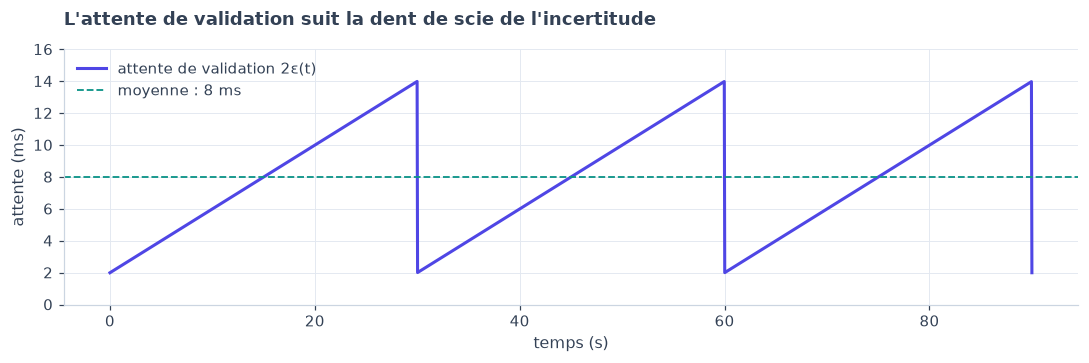

,eps_max_ms,eps_moy_ms,attente_moy_ms,débit_max_tx_s
configuration,,,,
synchro toutes les 30 s,7.0,4.0,8.0,125.0
synchro toutes les 5 s,2.0,1.5,3.0,333.6
NTP sur Internet,50.0,50.0,100.0,10.0


In [3]:
rows = []
for nom, base, sync in [("synchro toutes les 30 s", 1e-3, 30), ("synchro toutes les 5 s", 1e-3, 5),
                        ("NTP sur Internet", 50e-3, 1e9)]:
    tt = ds.TrueTime(base=base, drift_ppm=200 if sync < 1e8 else 0, sync_every=sync)
    grid = np.linspace(0, 300, 30_001)
    eps = np.array([tt.epsilon(g) for g in grid])
    rows.append(dict(configuration=nom, eps_max_ms=eps.max() * 1e3, eps_moy_ms=eps.mean() * 1e3,
                     attente_moy_ms=2 * eps.mean() * 1e3, débit_max_tx_s=1 / (2 * eps.mean())))
C8 = pd.DataFrame(rows).set_index("configuration")
sans = ds.commit_wait_experiment(eps=4e-3, gap=2e-3, commit_wait=False, seed=3)
avec = ds.commit_wait_experiment(eps=4e-3, gap=2e-3, commit_wait=True, seed=3)
print(f"ε = 4 ms : inversions causales sans attente {sans['inversions']:.1%}, avec attente {avec['inversions']:.1%} "
      f"(attente moyenne {avec['attente_moy'] * 1e3:.1f} ms)")
tt = ds.TrueTime(base=1e-3, drift_ppm=200, sync_every=30)
g = np.linspace(0, 90, 2000)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(g, [2 * tt.epsilon(x) * 1e3 for x in g], color=INDIGO, label="attente de validation 2ε(t)")
ax.axhline(8, color=TEAL, ls="--", lw=1.2, label="moyenne : 8 ms")
ax.set_xlabel("temps (s)"); ax.set_ylabel("attente (ms)"); ax.set_ylim(0, 16)
ax.set_title("L'attente de validation suit la dent de scie de l'incertitude")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
C8.round(1)

> **À retenir.** Le commit wait coûte $2\varepsilon$ par validation et borne le débit des
> transactions dépendantes à environ $1/(2\bar\varepsilon)$ : réduire l'incertitude des
> horloges, c'est gagner directement en latence et en débit.

## Exercice 8.9 : bail, pause et marge

**Énoncé.** Un client détient des baux de 10 s. Avant chaque écriture, il vérifie qu'il
reste au moins $m$ secondes sur son bail, puis écrit. Entre la vérification et l'écriture,
le processus peut faire une pause dont la durée suit `ds.gc_pause_samples` : quelques
millisecondes en général, et avec probabilité $2 \times 10^{-3}$ une longue pause de Pareto,
$P(\text{pause} > x) = (2/x)^{1{,}5}$ pour $x \geq 2$ s. Le temps restant $R$ au moment de la
vérification est uniforme sur $[m, 10]$.

1. Exprimer la probabilité qu'une écriture arrive **après** l'expiration du bail, puis la
   calculer pour $m \in \{0{,}5 ; 2 ; 5 ; 9\}$ s.
2. Le client écrit 100 fois par seconde. Combien d'écritures hors bail par jour ?
3. Vérifier par simulation, et confirmer avec `ds.lease_scenario` qu'un stockage à jetons
   de clôture rend ces écritures inoffensives.

**Rappels.** Pauses de processus, boucle naïve du bail (cours 4, section 1 ; section
*Process Pauses*) ; jetons de clôture (cours 4, section 5 ; section *Fencing tokens*).

**Solution.**

*1.* L'écriture est hors bail si la pause dépasse le temps restant :
$P = \mathbb{E}_R[P(\text{pause} > R)] = \frac{1}{10 - m}\int_m^{10} 2 \times 10^{-3} \min\left(1, (2/r)^{1{,}5}\right) dr$
(les petites pauses de quelques millisecondes ne comptent pas dès que $m \gg 10$ ms).
Pour $m \geq 2$ : $\int_m^{10} (2/r)^{1{,}5} dr = 2^{1{,}5} \times 2 (m^{-1/2} - 10^{-1/2})$.

*2.* À 100 écritures/s, $8{,}64 \times 10^6$ écritures par jour : il suffit de multiplier.

*3.* Voir ci-dessous. Augmenter la marge réduit le risque (d'un facteur 3 environ entre
2 et 9 s) mais ne l'annule **jamais** : la queue de la loi des pauses n'est pas bornée. Et
une grande marge gaspille le bail (à $m = 9$ s, on renouvelle le bail toutes les
secondes). Avec des jetons de clôture vérifiés par le stockage, une écriture hors bail
est refusée dès qu'un jeton plus récent a été utilisé : le risque résiduel disparaît.

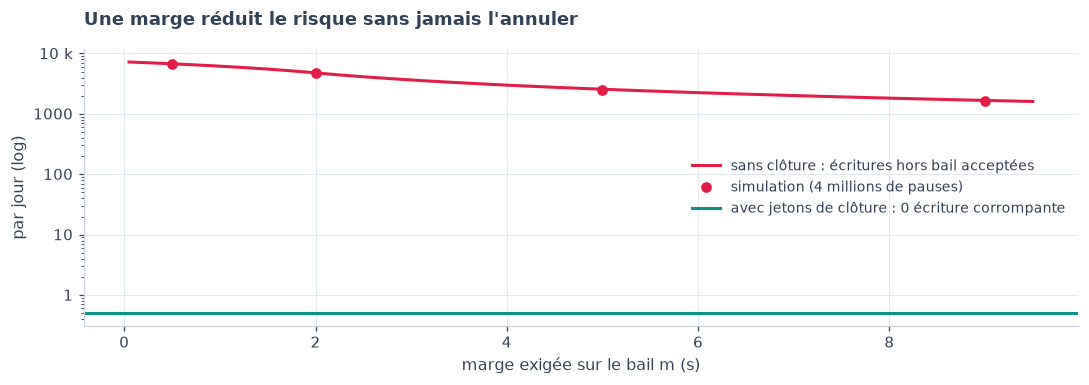

,P_formule,P_simulée,par_jour
marge_s,,,
0.5,0.0008,0.0008,6750.3786
2.0,0.0006,0.0006,4776.0746
5.0,0.0003,0.0003,2560.7845
9.0,0.0002,0.0002,1672.0768


clôture,False,True
pause,,
3.0,0,0
9.5,0,0
15.0,1,0


In [4]:
def p_hors_bail(m, L=10.0):
    r = np.linspace(m, L, 20_001)
    return np.trapezoid(2e-3 * np.minimum(1, (2 / r) ** 1.5), r) / (L - m)

rows = []
pauses = ds.gc_pause_samples(4_000_000, seed=4)
for m in (0.5, 2, 5, 9):
    R = rng.uniform(m, 10, pauses.size)
    rows.append(dict(marge_s=m, P_formule=p_hors_bail(m), P_simulée=np.mean(pauses > R),
                     par_jour=p_hors_bail(m) * 100 * 86_400))
P9 = pd.DataFrame(rows).set_index("marge_s")
ms = np.linspace(0.05, 9.5, 100)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.semilogy(ms, [p_hors_bail(m) * 8.64e6 for m in ms], color=ROSE, label="sans clôture : écritures hors bail acceptées")
ax.semilogy(P9.index, P9.P_simulée * 8.64e6, "o", color=ROSE, label="simulation (4 millions de pauses)")
ax.axhline(0.5, color=TEAL, lw=2, label="avec jetons de clôture : 0 écriture corrompante")
plain_log_axis(ax, "y")
ax.set_xlabel("marge exigée sur le bail m (s)"); ax.set_ylabel("par jour (log)")
ax.set_title("Une marge réduit le risque sans jamais l'annuler")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
verif = []
for pause in (3.0, 9.5, 15.0):
    for f in (False, True):
        _, lock, store, _ = ds.lease_scenario(fencing=f, pause=pause)
        verif.append(dict(pause=pause, clôture=f, écritures_dans_le_désordre=len(ds.token_order_violations(store))))
display(P9.round(5))
pd.DataFrame(verif).pivot(index="pause", columns="clôture", values="écritures_dans_le_désordre")

La simulation confirme la formule : près de 7 000 écritures hors bail par jour avec une
marge d'une demi-seconde, encore plus de 1 600 avec 9 s de marge. La vérification avec
`ds.lease_scenario` montre qu'une pause de 15 s produit une écriture dans le désordre sans
clôture, et aucune avec.

> **À retenir.** La marge d'un bail ne fait que raréfier les écritures de zombie, car la
> durée des pauses n'est pas bornée. Seule une vérification **côté ressource** (jeton de
> clôture) les rend inoffensives.

## Exercice 8.10 : majorités, menteurs et propriétés

**Énoncé.**

1. Combien de nœuds faut-il au minimum pour tolérer $f = 1, 2, 3$ pannes franches ? Et $f$
   nœuds byzantins ?
2. Une équipe propose 4 nœuds avec des quorums de 2 « pour aller plus vite ». Montrer le
   danger. Quelle taille minimale $q$ de quorum garantit que deux quorums se recoupent ?
   Avec $f$ nœuds byzantins, il faut que l'intersection contienne au moins un nœud
   **honnête** : quelle condition sur $q$ ?
3. Classer en sûreté ou vivacité : (a) au plus un leader par mandat ; (b) toute écriture
   acquittée finit par être visible de tous les lecteurs ; (c) aucun jeton n'est distribué
   deux fois ; (d) toute requête reçoit une réponse en moins de 100 ms ; (e) si une majorité
   est joignable, un leader finit par être élu ; (f) le solde d'un compte n'est jamais
   négatif.
4. Pourquoi un protocole byzantin à 4 nœuds ne protège-t-il pas d'un bogue logiciel ?

**Rappels.** Quorums majoritaires (cours 4, section 3) ; fautes byzantines, $n > 3f$
(cours 5, sections 1 et 2) ; sûreté et vivacité (cours 5, section 5 ; section
*Safety and liveness*).

**Solution.**

*1.* Pannes franches : $n = 2f + 1$, soit 3, 5, 7. Byzantin : $n = 3f + 1$, soit 4, 7, 10.

*2.* Avec 4 nœuds et $q = 2$, les quorums $\{1, 2\}$ et $\{3, 4\}$ sont disjoints : lors
d'une partition 2 contre 2, chaque moitié peut décider seule (cerveau divisé). Deux
quorums se recoupent si $2q > n$, soit $q > n/2$ : $q = 3$ pour 4 nœuds (ce qui ne tolère
qu'une panne, comme avec 3 nœuds). Avec $f$ byzantins, l'intersection doit contenir au
moins $f + 1$ nœuds : $2q - n \geq f + 1$, soit $q \geq \lceil (n + f + 1)/2 \rceil$ ; pour
$n = 4$, $f = 1$ : $q = 3$.

*3.* Sûreté : (a), (c), (d) et (f) ; chacune peut être violée à un instant précis, de façon
irréversible. Le cas (d) surprend : « en moins de 100 ms » est une **borne**, donc on peut
dater la violation (la 101e milliseconde) ; c'est une propriété de sûreté. Vivacité : (b)
et (e), qui contiennent « finit par ».

*4.* Tous les nœuds exécutent le même logiciel : un bogue déclenché par une entrée donnée
frappe les 4 en même temps, et la condition « au plus 1 nœud fautif » est violée. Il
faudrait 4 implémentations indépendantes.

quorums disjoints pour n = 4, q = 2 : ({0, 1}, {2, 3})


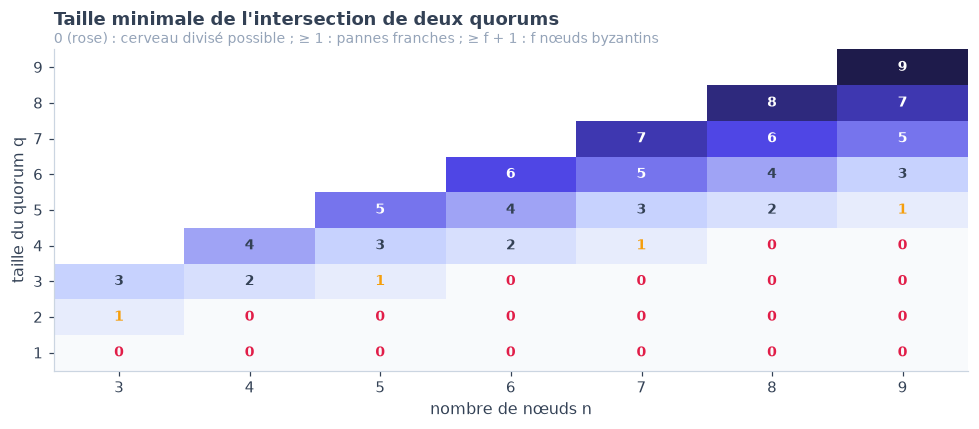

,pannes franches : n min,byzantin : n min,byzantin : q min (n = 3f+1)
f,,,
1,3,4,3
2,5,7,5
3,7,10,7


In [5]:
def quorums_disjoints(n, q):
    Q = [set(c) for c in itertools.combinations(range(n), q)]
    return next(((a, b) for a in Q for b in Q if not a & b), None)

def intersection_min(n, q):
    Q = [set(c) for c in itertools.combinations(range(n), q)]
    return min(len(a & b) for a in Q for b in Q)

rows = []
for n in range(3, 10):
    for q in range(1, n + 1):
        rows.append(dict(n=n, q=q, intersection_min=intersection_min(n, q)))
I = pd.DataFrame(rows).pivot(index="q", columns="n", values="intersection_min")
print("quorums disjoints pour n = 4, q = 2 :", quorums_disjoints(4, 2))
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(I.values, cmap="ddia_seq", origin="lower", aspect="auto")
for i, q in enumerate(I.index):
    for j, n in enumerate(I.columns):
        v = I.loc[q, n]
        if not np.isnan(v):
            col = ROSE if v == 0 else (AMBER if v == 1 else SLATE)
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v >= 5 else col,
                    fontweight="bold")
ax.set_xticks(range(len(I.columns))); ax.set_xticklabels(I.columns)
ax.set_yticks(range(len(I.index))); ax.set_yticklabels(I.index)
ax.set_xlabel("nombre de nœuds n"); ax.set_ylabel("taille du quorum q"); ax.grid(False)
ax.set_title("Taille minimale de l'intersection de deux quorums")
subtitle(ax, "0 (rose) : cerveau divisé possible ; ≥ 1 : pannes franches ; ≥ f + 1 : f nœuds byzantins")
plt.tight_layout(); plt.show()
pd.DataFrame({"f": [1, 2, 3], "pannes franches : n min": [2 * f + 1 for f in (1, 2, 3)],
              "byzantin : n min": [3 * f + 1 for f in (1, 2, 3)],
              "byzantin : q min (n = 3f+1)": [math.ceil((3 * f + 1 + f + 1) / 2) for f in (1, 2, 3)]}).set_index("f")

La table confirme : l'intersection minimale vaut $2q - n$ (quand c'est positif). Pour
$n = 4$, il faut $q = 3$ pour une intersection de 2 nœuds, dont au moins un honnête si un
seul nœud ment.

> **À retenir.** Deux quorums de taille $q$ parmi $n$ se recoupent sur au moins $2q - n$
> nœuds : $q > n/2$ suffit contre les pannes, $2q - n \geq f + 1$ contre $f$ menteurs. Une
> borne de temps est une propriété de sûreté ; « finit par » signale la vivacité.